In [2]:

import os, time, random, json, zipfile, pickle, copy, tarfile, subprocess, gc, hashlib, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from scipy.ndimage import gaussian_filter
from scipy import stats
from IPython.display import display


MODE = 'manuscript'
RUN_ID = 'RG_ATTL_CIFAR100_ONLY_v1'

MOUNT_DRIVE = False

# Files uploaded through the Colab sidebar are stored here.
BASE = Path('/content')

# Dataset location
DATA_FOLDER = BASE

# Save experimental outputs to Colab local storage.
ROOT = BASE / 'RG_ATTL_FINAL_RESULTS' / RUN_ID / MODE
ROOT.mkdir(parents=True, exist_ok=True)

# Select GPU automatically when available.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
torch.set_num_threads(2)


CFG = {
    'verify': dict(
        train_n=1500,
        val_n=200,
        test_n=96,
        epochs=1,
        batch=64,
        seeds=[17],
        corruption_types=[
            'gaussian_noise',
            'defocus_blur',
            'brightness'
        ],
        severities=[1, 3, 5],
        train_stop_accuracy=0.,
        batch_steps=1
    ),

    'manuscript': dict(
        train_n=45000,
        val_n=5000,
        test_n=10000,
        epochs=25,
        batch=128,
        seeds=[17, 23, 41],
        corruption_types=[
            'gaussian_noise',
            'defocus_blur',
            'brightness',
            'motion_blur',
            'fog',
            'contrast',
            'jpeg_compression'
        ],
        severities=[1, 2, 3, 4, 5],
        train_stop_accuracy=0.,
        batch_steps=1
    )
}

conf = CFG[MODE]

TRAIN_N = conf['train_n']
VAL_N = conf['val_n']
TEST_N = conf['test_n']
EPOCHS = conf['epochs']
BATCH = conf['batch']
SEEDS = conf['seeds']



RUN_CIFAR100 = True
RUN_CIFAR10 = False
RUN_CIFAR10C = False

SCENARIOS = [
    'abrupt',
    'gradual',
    'recurring'
]

METHODS = [
    'source',
    'tent',
    'eata_reference',
    'sar_reference',
    'reliability_only',
    'adaptive_rate_only',
    'rg_attl'
]



C100_PATH = None
C10_PATH = None
C10C_PATH = None

def find_input(spec, patterns):
    if spec is not None:
        path = Path(spec)
        return path if path.exists() else None

    for folder in [Path('/content'), Path('/content/RG_ATTL_DATA')]:
        if not folder.exists():
            continue

        for pattern in patterns:
            matches = sorted(folder.glob(pattern))

            if matches:
                return matches[0]

    return None

C100_PATH = find_input(
    C100_PATH,
    [
        'CIFAR-100 Python(2).zip',
        '*CIFAR-100*.zip',
        '*cifar*100*.zip',
        'cifar-100-python'
    ]
)

# Other datasets are disabled.
C10_PATH = None
C10C_PATH = None

print('=' * 65)
print('RG-ATTL CIFAR-100 EXPERIMENT')
print('=' * 65)

print('MODE:', MODE)
print('DEVICE:', DEVICE)
print('OUTPUT DIRECTORY:', ROOT)
print('CIFAR-100 DATASET:', C100_PATH)
print('CIFAR-10:', 'DISABLED')
print('CIFAR-10-C:', 'DISABLED')
print('TRAINING SAMPLES:', TRAIN_N)
print('VALIDATION SAMPLES:', VAL_N)
print('TEST SAMPLES:', TEST_N)
print('EPOCHS:', EPOCHS)
print('BATCH SIZE:', BATCH)
print('SEEDS:', SEEDS)
print('SCENARIOS:', SCENARIOS)
print('METHODS:', METHODS)

assert C100_PATH is not None and C100_PATH.exists(), (
    'CIFAR-100 ZIP not found. Upload it using the '
    'Google Colab Files sidebar under /content/.'
)


def seed_all(v):
    random.seed(v)
    np.random.seed(v)
    torch.manual_seed(v)

    if DEVICE == 'cuda':
        torch.cuda.manual_seed_all(v)

seed_all(SEEDS[0])


config_data = {
    'run_id': RUN_ID,
    'mode': MODE,
    'device': DEVICE,
    'config': conf,
    'dataset': str(C100_PATH),
    'methods': METHODS,
    'scenarios': SCENARIOS,
    'storage': 'Google Colab local files'
}

(ROOT / 'config.json').write_text(
    json.dumps(config_data, indent=2)
)

print('\nDataset located successfully.')
print('Configuration saved successfully.')
print('Ready for CIFAR-100 loading and model training.')


RG-ATTL CIFAR-100 EXPERIMENT
MODE: manuscript
DEVICE: cuda
OUTPUT DIRECTORY: /content/RG_ATTL_FINAL_RESULTS/RG_ATTL_CIFAR100_ONLY_v1/manuscript
CIFAR-100 DATASET: /content/CIFAR-100 Python.zip
CIFAR-10: DISABLED
CIFAR-10-C: DISABLED
TRAINING SAMPLES: 45000
VALIDATION SAMPLES: 5000
TEST SAMPLES: 10000
EPOCHS: 25
BATCH SIZE: 128
SEEDS: [17, 23, 41]
SCENARIOS: ['abrupt', 'gradual', 'recurring']
METHODS: ['source', 'tent', 'eata_reference', 'sar_reference', 'reliability_only', 'adaptive_rate_only', 'rg_attl']

Dataset located successfully.
Configuration saved successfully.
Ready for CIFAR-100 loading and model training.


In [3]:
import io, csv, tempfile, shutil
from PIL import Image
class RawCifar(Dataset):
    def __init__(self,x,y,orig_ids=None):
        self.x=np.asarray(x,dtype=np.uint8);self.y=np.asarray(y,dtype=np.int64)
        self.orig_ids=np.arange(len(y)) if orig_ids is None else np.asarray(orig_ids)
    def __len__(self):return len(self.y)
    def __getitem__(self,i):return transforms.functional.to_tensor(self.x[i]),int(self.y[i])
def get_pickle_from_zip(path,name):
    with zipfile.ZipFile(path) as z:
        key=next((k for k in z.namelist() if k.endswith('/'+name) or k==name),None)
        if key is None:raise KeyError(f'{name} not in {path}')
        return pickle.loads(z.read(key),encoding='bytes')
def unpack_batch(d,labels_key):
    return d[b'data'].reshape(-1,3,32,32).transpose(0,2,3,1),np.asarray(d[labels_key],dtype=np.int64)
def read_c100(path):
    if path.is_file() and path.suffix.lower()=='.zip':
        return unpack_batch(get_pickle_from_zip(path,'train'),b'fine_labels'),unpack_batch(get_pickle_from_zip(path,'test'),b'fine_labels')
    raise ValueError('CIFAR-100 input must be the supplied CIFAR-100 Python ZIP.')
def read_c10_python_folder(folder):
    folder=Path(folder)
    if not (folder/'data_batch_1').exists():
        matches=list(folder.glob('**/data_batch_1'))
        if not matches:raise FileNotFoundError('CIFAR-10 Python batches missing')
        folder=matches[0].parent
    arrays=[unpack_batch(pickle.loads((folder/f'data_batch_{i}').read_bytes(),encoding='bytes'),b'labels') for i in range(1,6)]
    return (np.concatenate([a[0] for a in arrays]),np.concatenate([a[1] for a in arrays])),unpack_batch(pickle.loads((folder/'test_batch').read_bytes(),encoding='bytes'),b'labels')
def read_c10_zip(path):
    with zipfile.ZipFile(path) as z:
        names=z.namelist()
        if any(k.endswith('data_batch_1') for k in names):
            arrays=[unpack_batch(pickle.loads(z.read(next(k for k in names if k.endswith(f'data_batch_{i}'))),encoding='bytes'),b'labels') for i in range(1,6)]
            tr=(np.concatenate([a[0] for a in arrays]),np.concatenate([a[1] for a in arrays]))
            te=unpack_batch(pickle.loads(z.read(next(k for k in names if k.endswith('test_batch'))),encoding='bytes'),b'labels')
            return tr,te
        # Kaggle competition ZIP: trainLabels.csv and numbered image files (not necessarily full 50K)
        label_paths=[k for k in names if k.endswith('trainLabels.csv')]
        if not label_paths:raise ValueError('ZIP does not contain CIFAR-10 Python batches or trainLabels.csv.')
        rows=list(csv.DictReader(io.StringIO(z.read(label_paths[0]).decode('utf8'))))
        cls=sorted(set(r['label'] for r in rows)); cmap={v:i for i,v in enumerate(cls)}
        imgs=[];targets=[]
        for r in rows:
            image_name=next((k for k in names if k.endswith('/'+r['id']+'.png') or k==r['id']+'.png'),None)
            if image_name is None:continue
            imgs.append(np.asarray(Image.open(io.BytesIO(z.read(image_name))).convert('RGB').resize((32,32))))
            targets.append(cmap[r['label']])
        if not imgs:raise ValueError('Kaggle ZIP has labels but no PNG training images. Use train.7z + trainLabels.csv directory.')
        return (np.stack(imgs),np.array(targets)),None
def read_c10_kaggle_dir(folder):
    folder=Path(folder)
    label_file=next(iter(folder.glob('**/trainLabels.csv')),None)
    if label_file is None:raise FileNotFoundError('trainLabels.csv missing from Kaggle directory')
    df=pd.read_csv(label_file); class_names=sorted(df.label.unique()); cmap={v:i for i,v in enumerate(class_names)}
    image_dir=next((p for p in folder.glob('**/train') if p.is_dir() and any(p.glob('*.png'))),None)
    if image_dir is None:
        archive=next(iter(folder.glob('**/train.7z')),None)
        if archive is None:raise FileNotFoundError('No numbered Kaggle PNG files or train.7z next to labels.')
        image_dir=Path('/content/rg_attl_c10_train');image_dir.mkdir(parents=True,exist_ok=True)
        if not any(image_dir.glob('*.png')):
            subprocess.run(['7z','x',str(archive),'-o'+str(image_dir),'-y'],check=True,stdout=subprocess.DEVNULL)
        nested=list(image_dir.glob('**/train'))
        if nested and any(nested[0].glob('*.png')):image_dir=nested[0]
    rng=np.random.default_rng(SEEDS[0]);sample=min(len(df),max(TRAIN_N+VAL_N+TEST_N,5500))
    subset=df.iloc[np.sort(rng.choice(len(df),size=sample,replace=False))]
    x=[];y=[]
    for item in subset.itertuples(index=False):
        f=image_dir/f'{item.id}.png'
        if f.exists():x.append(np.asarray(Image.open(f).convert('RGB')));y.append(cmap[item.label])
    if len(x)<TRAIN_N+VAL_N+TEST_N:raise RuntimeError(f'Insufficient labeled images found: {len(x)}')
    return (np.stack(x),np.array(y)),None

def read_c10(path):
    if path.is_dir():
        if list(path.glob('**/data_batch_1')):return read_c10_python_folder(path)
        return read_c10_kaggle_dir(path)
    if path.suffix.lower()=='.zip':return read_c10_zip(path)
    if path.name in ('train.7z','trainLabels.csv'):
        return read_c10_kaggle_dir(path.parent)
    if path.name=='cifar-10-python.tar.gz':
        with tarfile.open(path,'r:gz') as z:
            td=Path('/content/c10_python_extracted');td.mkdir(exist_ok=True)
            z.extractall(td,filter='data')
        return read_c10_python_folder(td)
    raise ValueError('Unsupported CIFAR-10 input. Set C10_PATH to labeled Kaggle ZIP/folder or original CIFAR-10 Python archive.')

def get_cifar(name):
    (xt,yt),test=read_c100(C100_PATH) if name=='CIFAR-100' else read_c10(C10_PATH)
    rng=np.random.default_rng(SEEDS[0]);perm=rng.permutation(len(yt))
    n_train=min(TRAIN_N,len(yt)-VAL_N-(TEST_N if test is None else 0));n_val=VAL_N
    if n_train<=0:raise ValueError('Not enough labeled source images')
    tridx,vaidx=perm[:n_train],perm[n_train:n_train+n_val]
    train=RawCifar(xt[tridx],yt[tridx]);val=RawCifar(xt[vaidx],yt[vaidx])
    if test is not None:
        xe,ye=test;ids=rng.permutation(len(ye))[:TEST_N]
        testds=RawCifar(xe[ids],ye[ids],orig_ids=ids)
        original_test_available=True
    else:
        ids=perm[n_train+n_val:n_train+n_val+TEST_N];testds=RawCifar(xt[ids],yt[ids],orig_ids=ids)
        original_test_available=False
    return train,val,testds,original_test_available
DATA={};TEST_ORIGINAL={}
for d in (['CIFAR-100'] if RUN_CIFAR100 else [])+(['CIFAR-10'] if RUN_CIFAR10 else []):
    a,b,c,o=get_cifar(d);DATA[d]=(a,b,c);TEST_ORIGINAL[d]=o
    print(d,'train',len(a),'validation',len(b),'test',len(c),'official CIFAR test:',o)
# Unlabeled Kaggle competition test data must never be assumed ground-truth labeled.


CIFAR-100 train 45000 validation 5000 test 10000 official CIFAR test: True


In [5]:
# ResNet-18 source models with restartable epoch checkpoints
from torchvision.models import resnet18
def model_for(name):
    n=100 if name=='CIFAR-100' else 10
    m=resnet18(weights=None,num_classes=n)
    m.conv1=nn.Conv2d(3,64,kernel_size=3,stride=1,padding=1,bias=False)
    m.maxpool=nn.Identity()
    return m

def source_model(name,train,val):
    p=ROOT/f'{name}_source_final.pt'; mid=ROOT/f'{name}_source_progress.pt';m=model_for(name).to(DEVICE)
    if p.exists():
        m.load_state_dict(torch.load(p,map_location=DEVICE,weights_only=True));print('Loaded final source',p);return m
    optimizer=torch.optim.SGD(m.parameters(),lr=.08,momentum=.9,weight_decay=5e-4)
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE=='cuda')
    start=0
    if mid.exists():
        st=torch.load(mid,map_location=DEVICE,weights_only=False)
        m.load_state_dict(st['model']);optimizer.load_state_dict(st['optimizer']);start=st['epoch'];print('Resuming',name,'epoch',start)
    loader=DataLoader(train,batch_size=BATCH,shuffle=True,num_workers=2,pin_memory=DEVICE=='cuda')
    for epoch in range(start,EPOCHS):
        seed_all(101+epoch)
        m.train();running=0.;count=0
        for x,y in loader:
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type='cuda',enabled=DEVICE=='cuda'):
                logits=m(x);loss=F.cross_entropy(logits,y)
            scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
            running+=float((logits.argmax(1)==y).sum());count+=len(y)
        if DEVICE=='cuda':torch.cuda.synchronize()
        print(f'{name} epoch {epoch+1}/{EPOCHS}: train accuracy {running/count:.3f}')
        torch.save({'model':m.state_dict(),'optimizer':optimizer.state_dict(),'epoch':epoch+1},mid)
    torch.save(m.cpu().state_dict(),p);m=m.to(DEVICE)
    return m
SOURCES={name:source_model(name,tr,va) for name,(tr,va,te) in DATA.items()}
@torch.no_grad()
def evaluate_clean(m,dataset):
    m.eval();good=n=0
    for x,y in DataLoader(dataset,batch_size=BATCH,num_workers=2):
        p=m(x.to(DEVICE)).argmax(1).cpu();good+=(p==y).sum().item();n+=len(y)
    return good/max(1,n)
for name,(tr,va,te) in DATA.items():print(name,'held-out CLEAN source validation accuracy',round(evaluate_clean(SOURCES[name],va),4))


CIFAR-100 epoch 1/25: train accuracy 0.110
CIFAR-100 epoch 2/25: train accuracy 0.240
CIFAR-100 epoch 3/25: train accuracy 0.361
CIFAR-100 epoch 4/25: train accuracy 0.462
CIFAR-100 epoch 5/25: train accuracy 0.537
CIFAR-100 epoch 6/25: train accuracy 0.602
CIFAR-100 epoch 7/25: train accuracy 0.658
CIFAR-100 epoch 8/25: train accuracy 0.705
CIFAR-100 epoch 9/25: train accuracy 0.750
CIFAR-100 epoch 10/25: train accuracy 0.784
CIFAR-100 epoch 11/25: train accuracy 0.811
CIFAR-100 epoch 12/25: train accuracy 0.833
CIFAR-100 epoch 13/25: train accuracy 0.853
CIFAR-100 epoch 14/25: train accuracy 0.862
CIFAR-100 epoch 15/25: train accuracy 0.872
CIFAR-100 epoch 16/25: train accuracy 0.884
CIFAR-100 epoch 17/25: train accuracy 0.884
CIFAR-100 epoch 18/25: train accuracy 0.886
CIFAR-100 epoch 19/25: train accuracy 0.892
CIFAR-100 epoch 20/25: train accuracy 0.897
CIFAR-100 epoch 21/25: train accuracy 0.899
CIFAR-100 epoch 22/25: train accuracy 0.885
CIFAR-100 epoch 23/25: train accuracy 0.9

In [6]:
def corruption(x,kind,severity,seed):
    rng=np.random.default_rng(seed);img=x.numpy().transpose(1,2,0)
    if kind=='noise':img=np.clip(img+rng.normal(0,0.06+0.04*severity,img.shape),0,1)
    elif kind=='blur':img=gaussian_filter(img,sigma=(0.2+0.36*severity,0.2+0.36*severity,0))
    elif kind=='dark':img=np.clip(img*(1-0.12*severity),0,1)
    return torch.tensor(np.ascontiguousarray(img.transpose(2,0,1)),dtype=torch.float32)
def shift_schedule(scenario,n):
    out=[]
    for i in range(n):
        phase=min(3,4*i//n)
        if scenario=='abrupt':out.append((['noise','blur','dark','noise'][phase],3))
        elif scenario=='gradual':out.append(('noise',[1,2,3,4][phase]))
        else:out.append((['noise','dark','noise','blur'][phase],3))
    return out

def locate_c10c_folder(path):
    if path.is_dir():return path
    dest=Path('/content/RG_ATTL_OFFICIAL_C10C'); dest.mkdir(exist_ok=True)
    marker=dest/'.extraction_complete'
    if not marker.exists():
        print('Extracting your official CIFAR-10-C archive once; large archives need disk space.')
        if path.suffix.lower()=='.zip':
            with zipfile.ZipFile(path) as z:z.extractall(dest)
        else:
            with tarfile.open(path,'r:*') as t:t.extractall(dest,filter='data')
        marker.touch()
    return dest
C10C_DIR=None
if RUN_CIFAR10C:
    C10C_DIR=locate_c10c_folder(C10C_PATH)
    matches=list(C10C_DIR.glob('**/labels.npy'))
    if not matches:raise FileNotFoundError('CIFAR-10-C labels.npy is missing. Upload complete official archive.')
    C10C_DIR=matches[0].parent
    REQUIRED=conf['corruption_types']
    for k in REQUIRED:
        if not (C10C_DIR/f'{k}.npy').exists():raise FileNotFoundError(f'Missing {k}.npy in {C10C_DIR}')
    C10C_LABELS=np.load(C10C_DIR/'labels.npy',mmap_mode='r')
    if len(C10C_LABELS)!=10000:raise ValueError('Unexpected CIFAR-10-C labels shape')
    C10C_ARRAYS={k:np.load(C10C_DIR/f'{k}.npy',mmap_mode='r') for k in REQUIRED}
    rng=np.random.default_rng(SEEDS[0]+9)
    OFFICIAL_IDS=rng.permutation(10000)[:TEST_N]
    print('Official CIFAR-10-C source:',C10C_DIR)

def prepare_stream(name,scenario,test,official=False):
    schedule=shift_schedule(scenario,TEST_N if official else len(test));xx=[];yy=[];metadata=[]
    for i,(kind,sev) in enumerate(schedule):
        if official:
            mapping={'noise':'gaussian_noise','blur':'defocus_blur','dark':'brightness'}
            idx=int(OFFICIAL_IDS[i]); x=transforms.functional.to_tensor(np.asarray(C10C_ARRAYS[mapping[kind]][(sev-1)*10000+idx]).copy())
            y=int(C10C_LABELS[idx])
        else:
            raw,y=test[i];x=corruption(raw,kind,sev,SEEDS[0]+i)
        xx.append(x);yy.append(y);metadata.append((kind,sev))
    return torch.stack(xx),torch.tensor(yy),metadata
# Streams are constructed per experiment and are NOT all loaded into GPU memory.
DATASETS=['CIFAR-100']
def stream_for(name,scenario,seed):
    global OFFICIAL_IDS
    if name=='CIFAR-10-C_OFFICIAL':
        OFFICIAL_IDS=np.random.default_rng(seed+9).permutation(10000)[:TEST_N]
        return prepare_stream(name,scenario,None,official=True)
    return prepare_stream(name,scenario,DATA[name][2],official=False)
print('Datasets:',DATASETS,'synthetic shift types: noise, blur, dark')


Datasets: ['CIFAR-100'] synthetic shift types: noise, blur, dark


In [7]:
def entropy_of(z):
    p=F.softmax(z,1).clamp_min(1e-8)
    return -(p*p.log()).sum(1)
class Adapter:
    def __init__(self,source,method,gamma=1.0):
        self.gamma=gamma
        self.m=copy.deepcopy(source).to(DEVICE);self.m.eval();self.method=method
        for p in self.m.parameters():p.requires_grad_(False)
        trainable=[]
        for l in self.m.modules():
            if isinstance(l,nn.BatchNorm2d):
                l.eval() # stable source statistics; identical policy for each adapter
                l.weight.requires_grad_(True);l.bias.requires_grad_(True)
                trainable.extend([l.weight,l.bias])
        self.params=trainable;self.trainable=sum(p.numel() for p in trainable) if method!='source' else 0
        self.opt=None if method=='source' else torch.optim.SGD(trainable,lr=1e-3)
        self.anchor=[p.detach().clone() for p in trainable]
        self.prev_prob=None
    def step(self,x):
        # Evaluate before adaptation; no labels used until scoring.
        with torch.no_grad():
            out=self.m(x);pred=out.argmax(1);unc=entropy_of(out);r=1-unc/np.log(out.shape[1]);R=r.mean().item()
        info={'reliability':R,'lr':0.,'selected':0.}
        if self.method=='source':return pred.cpu(),info
        filt=self.method in ['eata_reference','reliability_only','rg_attl']
        adap=self.method in ['adaptive_rate_only','rg_attl']
        selected=(r>=0.20).float() if filt else torch.ones_like(r)
        if self.method=='eata_reference' and self.prev_prob is not None:
            similarity=F.cosine_similarity(out.softmax(1).detach(),self.prev_prob[None,:],dim=1)
            selected*= (similarity<0.95).float()
        lr=0.0002+0.0018*(R**self.gamma) if adap else 0.001
        info.update(lr=float(lr),selected=float(selected.mean()))
        self.prev_prob=out.softmax(1).detach().mean(0)
        if selected.sum()<1:return pred.cpu(),info
        self.opt.param_groups[0]['lr']=lr
        # Update using only current unlabeled images and pre-update selection.
        self.opt.zero_grad(set_to_none=True)
        q=self.m(x);h=entropy_of(q)
        loss=(h*selected.detach()).sum()/selected.sum().clamp_min(1.)
        if self.method=='eata_reference':
            # Fisher-like weight anchoring surrogate, not author-provided Fisher estimate.
            loss=loss+0.0001*sum((a-b).square().sum() for a,b in zip(self.params,self.anchor))
        loss.backward()
        if self.method=='sar_reference':
            # Sharpness-aware two-pass update (SAM-style), adapted to restricted BN parameters.
            norm=torch.norm(torch.stack([p.grad.norm() for p in self.params if p.grad is not None]))
            rho=0.05
            with torch.no_grad():
                offsets=[]
                for p in self.params:
                    e=rho*p.grad/(norm+1e-12) if p.grad is not None else torch.zeros_like(p)
                    p.add_(e);offsets.append(e)
            self.opt.zero_grad(set_to_none=True)
            loss2=entropy_of(self.m(x)).mean();loss2.backward()
            with torch.no_grad():
                for p,e in zip(self.params,offsets):p.sub_(e)
        torch.nn.utils.clip_grad_norm_(self.params,1.)
        self.opt.step()
        return pred.cpu(),info


In [8]:
import itertools
records=[];timings=[]
JOBS=list(itertools.product(SEEDS,DATASETS,SCENARIOS,METHODS))
print('Total independently resumable jobs:',len(JOBS))
for jobnum,(seed,name,scenario,method) in enumerate(JOBS,1):
    tag=f's{seed}_{name}_{scenario}_{method}'
    predfile=ROOT/f'{tag}.csv';statsfile=ROOT/f'{tag}.json'
    if predfile.exists() and statsfile.exists():
        records.append(pd.read_csv(predfile));timings.append(json.loads(statsfile.read_text()));continue
    seed_all(seed)
    images,truth,metadata=stream_for(name,scenario,seed)
    source=SOURCES['CIFAR-10'] if name=='CIFAR-10-C_OFFICIAL' else SOURCES[name]
    adapter=Adapter(source,method);batch_rows=[]
    start=time.perf_counter()
    for beg in range(0,len(images),BATCH):
        x=images[beg:beg+BATCH].to(DEVICE);pred,info=adapter.step(x)
        for j,p in enumerate(pred.tolist()):
            idx=beg+j;kind,sev=metadata[idx]
            batch_rows.append({'seed':seed,'dataset':name,'scenario':scenario,'method':method,'index':idx,
               'phase':min(3,4*idx//len(images)),'corruption':kind,'severity':sev,
               'true':int(truth[idx]),'pred':int(p),'correct':int(p==int(truth[idx])),**info})
    if DEVICE=='cuda':torch.cuda.synchronize()
    dur=time.perf_counter()-start
    df=pd.DataFrame(batch_rows)
    sf={'seed':seed,'dataset':name,'scenario':scenario,'method':method,'time_s':dur,
       'trainable_parameters':adapter.trainable,'n_predictions':len(df)}
    df.to_csv(predfile,index=False);statsfile.write_text(json.dumps(sf,indent=2))
    records.append(df);timings.append(sf)
    print(f'[{jobnum}/{len(JOBS)}] {tag}: accuracy {df.correct.mean():.3f} | {dur:.1f}s')
    del adapter,images,truth;gc.collect()
    if DEVICE=='cuda':torch.cuda.empty_cache()
PRED=pd.concat(records,ignore_index=True);PERF=pd.DataFrame(timings)
PRED.to_csv(ROOT/'predictions_all.csv',index=False)
PERF.to_csv(ROOT/'computational_cost.csv',index=False)
print('Saved individual files and consolidated CSVs to',ROOT)


Total independently resumable jobs: 63
[1/63] s17_CIFAR-100_abrupt_source: accuracy 0.146 | 3.1s
[2/63] s17_CIFAR-100_abrupt_tent: accuracy 0.144 | 10.3s
[3/63] s17_CIFAR-100_abrupt_eata_reference: accuracy 0.145 | 10.4s
[4/63] s17_CIFAR-100_abrupt_sar_reference: accuracy 0.144 | 17.6s
[5/63] s17_CIFAR-100_abrupt_reliability_only: accuracy 0.144 | 10.3s
[6/63] s17_CIFAR-100_abrupt_adaptive_rate_only: accuracy 0.143 | 10.3s
[7/63] s17_CIFAR-100_abrupt_rg_attl: accuracy 0.143 | 10.2s
[8/63] s17_CIFAR-100_gradual_source: accuracy 0.051 | 3.1s
[9/63] s17_CIFAR-100_gradual_tent: accuracy 0.046 | 10.3s
[10/63] s17_CIFAR-100_gradual_eata_reference: accuracy 0.048 | 10.3s
[11/63] s17_CIFAR-100_gradual_sar_reference: accuracy 0.047 | 17.6s
[12/63] s17_CIFAR-100_gradual_reliability_only: accuracy 0.046 | 10.3s
[13/63] s17_CIFAR-100_gradual_adaptive_rate_only: accuracy 0.043 | 10.3s
[14/63] s17_CIFAR-100_gradual_rg_attl: accuracy 0.043 | 10.3s
[15/63] s17_CIFAR-100_recurring_source: accuracy 0.15

Table II


,dataset,scenario,method,mean_accuracy,sd_accuracy,seeds,n_per_seed
0,CIFAR-100,abrupt,adaptive_rate_only,0.1428,0.0,3,10000
1,CIFAR-100,abrupt,eata_reference,0.1448,0.0,3,10000
2,CIFAR-100,abrupt,reliability_only,0.1442,0.0,3,10000
3,CIFAR-100,abrupt,rg_attl,0.1428,0.0,3,10000
4,CIFAR-100,abrupt,sar_reference,0.1443,0.0,3,10000
5,CIFAR-100,abrupt,source,0.1465,0.0,3,10000
6,CIFAR-100,abrupt,tent,0.1442,0.0,3,10000
7,CIFAR-100,gradual,adaptive_rate_only,0.0433,0.0,3,10000
8,CIFAR-100,gradual,eata_reference,0.0484,0.0,3,10000
9,CIFAR-100,gradual,reliability_only,0.0465,0.0,3,10000


Table III


method               adaptive_rate_only  reliability_only  rg_attl  source  \
dataset   scenario                                                           
CIFAR-100 abrupt                 0.1428            0.1442   0.1428  0.1465   
          gradual                0.0433            0.0465   0.0433  0.0509   
          recurring              0.1505            0.1523   0.1505  0.1534   

method                 tent  
dataset   scenario           
CIFAR-100 abrupt     0.1442  
          gradual    0.0465  
          recurring  0.1523

Table IV


,method,mean_time_s,sd_time_s,trainable_parameters
0,adaptive_rate_only,10.257140,0.020964,9600
1,eata_reference,10.364668,0.034710,9600
2,reliability_only,10.293694,0.025307,9600
3,rg_attl,10.262407,0.015381,9600
4,sar_reference,17.575853,0.021939,9600
5,source,3.143616,0.007806,0
6,tent,10.307034,0.014534,9600


Paired intervals


,dataset,scenario,competitor,n_seeds,mean_accuracy_difference,ci95_low,ci95_high
0,CIFAR-100,abrupt,source,3,-0.0037,NaN,NaN
1,CIFAR-100,abrupt,tent,3,-0.0014,NaN,NaN
2,CIFAR-100,abrupt,eata_reference,3,-0.0020,NaN,NaN
3,CIFAR-100,abrupt,sar_reference,3,-0.0015,NaN,NaN
4,CIFAR-100,abrupt,reliability_only,3,-0.0014,NaN,NaN
5,CIFAR-100,abrupt,adaptive_rate_only,3,0.0000,NaN,NaN
6,CIFAR-100,gradual,source,3,-0.0076,NaN,NaN
7,CIFAR-100,gradual,tent,3,-0.0032,NaN,NaN
8,CIFAR-100,gradual,eata_reference,3,-0.0051,NaN,NaN
9,CIFAR-100,gradual,sar_reference,3,-0.0037,NaN,NaN


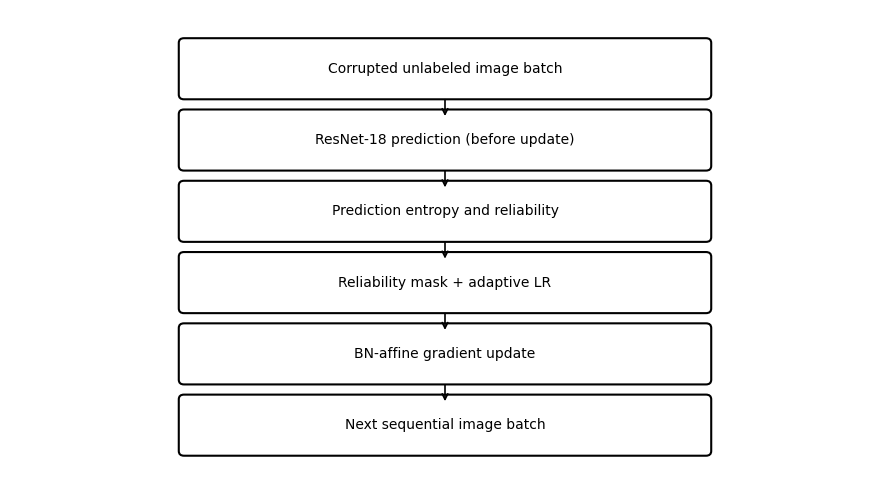

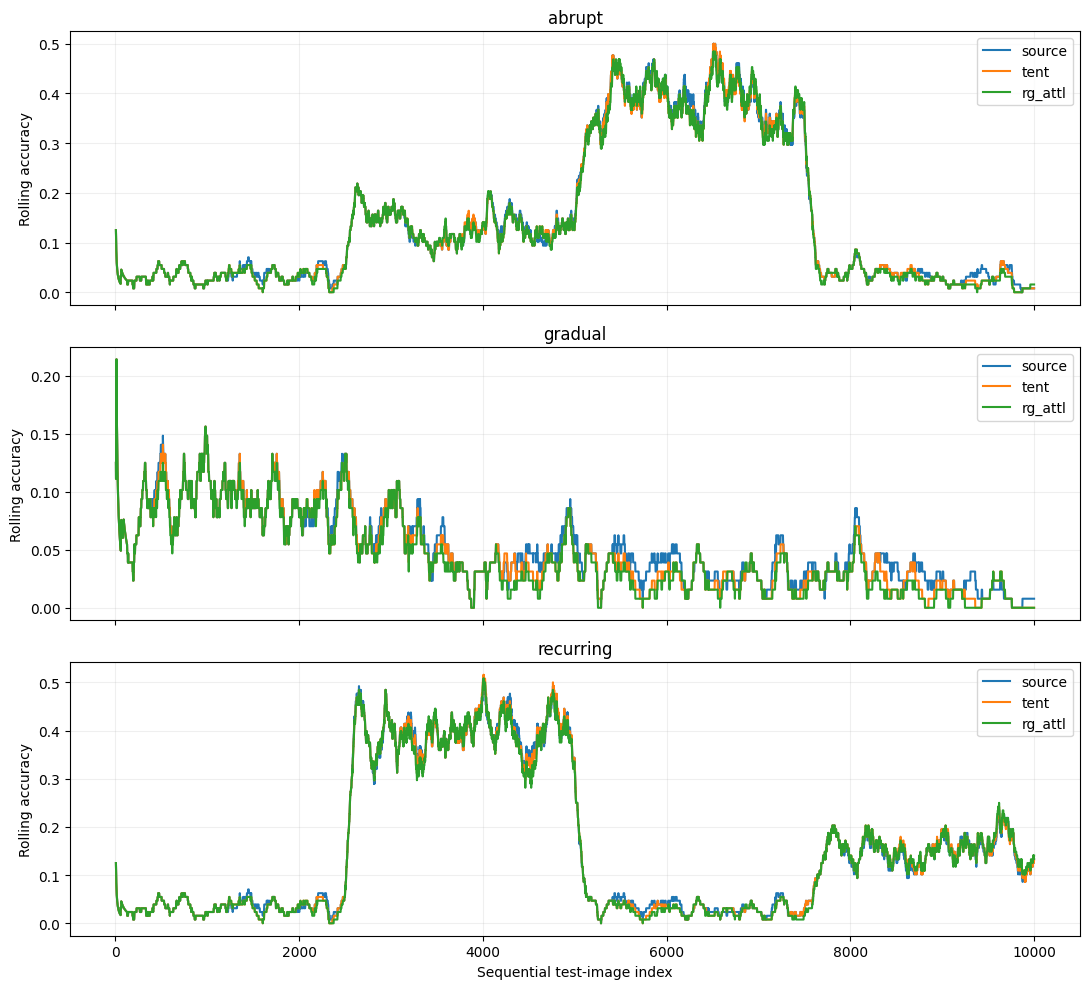

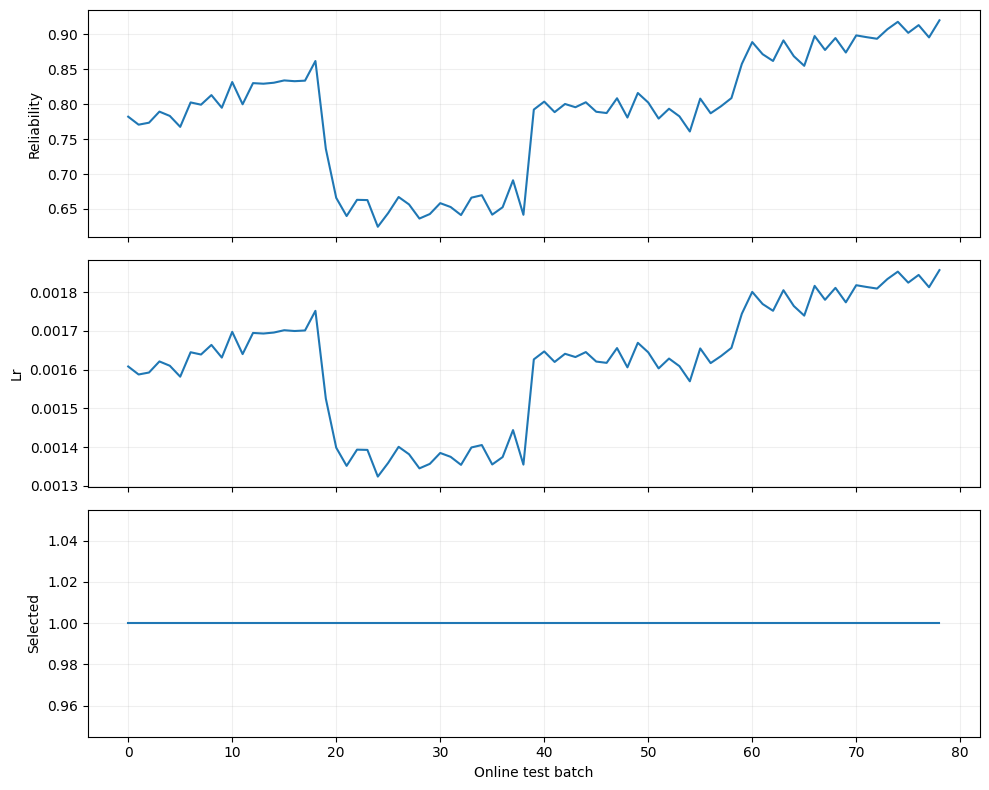

In [9]:
import matplotlib.patches as patches
from matplotlib import pyplot as plt
TABLE1=pd.DataFrame([
 ['Source-only','None','No','No','No'],['TENT','BN affine','No','No','No'],
 ['EATA reference variant','BN affine','Yes','No','Anchor penalty proxy'],
 ['SAR reference variant','BN affine','No','No','SAM-style 2 passes'],
 ['RG-ATTL','BN affine','Yes','Yes','No memory bank']],
 columns=['Method','Adapted parameters','Reliability filtering','Adaptive LR','Notes'])
TABLE1.to_csv(ROOT/'Table_I_methods.csv',index=False)
TABLE2=PRED.groupby(['dataset','scenario','method','seed'],as_index=False).agg(accuracy=('correct','mean'),n=('correct','size'))
TABLE2['error_rate']=1-TABLE2.accuracy;TABLE2.to_csv(ROOT/'Table_II_accuracy_by_seed.csv',index=False)
SUMMARY=TABLE2.groupby(['dataset','scenario','method'],as_index=False).agg(mean_accuracy=('accuracy','mean'),sd_accuracy=('accuracy','std'),seeds=('seed','nunique'),n_per_seed=('n','min'))
SUMMARY.to_csv(ROOT/'Table_II_summary.csv',index=False)
MAIN=['source','tent','reliability_only','adaptive_rate_only','rg_attl']
TABLE3=SUMMARY[SUMMARY.method.isin(MAIN)].pivot_table(index=['dataset','scenario'],columns='method',values='mean_accuracy')
TABLE3.to_csv(ROOT/'Table_III_ablations.csv')
TABLE4=PERF.groupby('method',as_index=False).agg(mean_time_s=('time_s','mean'),sd_time_s=('time_s','std'),trainable_parameters=('trainable_parameters','max'))
TABLE4.to_csv(ROOT/'Table_IV_efficiency.csv',index=False)
PAIRED=[]
for (dataset,scenario),t in TABLE2.groupby(['dataset','scenario']):
    a=t[t.method=='rg_attl'].set_index('seed').accuracy
    for method in [m for m in METHODS if m!='rg_attl']:
        b=t[t.method==method].set_index('seed').accuracy
        common=a.index.intersection(b.index)
        dif=(a.loc[common]-b.loc[common]).to_numpy(dtype=float)
        n=len(dif);mean=float(dif.mean()) if n else np.nan
        interval=stats.t.interval(.95,df=n-1,loc=mean,scale=stats.sem(dif)) if n>=3 and np.std(dif,ddof=1)>0 else (np.nan,np.nan)
        PAIRED.append({'dataset':dataset,'scenario':scenario,'competitor':method,'n_seeds':n,
                       'mean_accuracy_difference':mean,'ci95_low':interval[0],'ci95_high':interval[1]})
PAIR=pd.DataFrame(PAIRED);PAIR.to_csv(ROOT/'paired_seed_confidence_intervals.csv',index=False)
print('Table II');display(SUMMARY)
print('Table III');display(TABLE3)
print('Table IV');display(TABLE4)
print('Paired intervals');display(PAIR)
# Figure 1: Original algorithm schematic
fig,ax=plt.subplots(figsize=(9,5));ax.set(xlim=(0,10),ylim=(0,6));ax.axis('off')
steps=['Corrupted unlabeled image batch','ResNet-18 prediction (before update)','Prediction entropy and reliability',
       'Reliability mask + adaptive LR','BN-affine gradient update','Next sequential image batch']
for k,label in enumerate(steps):
    y=5.25-k*.91
    ax.add_patch(patches.FancyBboxPatch((2,y-.33),6,.66,boxstyle='round,pad=0.06',fill=False,lw=1.5))
    ax.text(5,y,label,ha='center',va='center',fontsize=10)
    if k<5:ax.annotate('',xy=(5,y-.64),xytext=(5,y-.36),arrowprops={'arrowstyle':'->','lw':1.2})
fig.tight_layout();fig.savefig(ROOT/'Figure_1_architecture.png',dpi=220);plt.show()
# Figure 2: Accuracy over sequential images, specific dataset/seed/scenario
name='CIFAR-100';seed=SEEDS[0]
fig,axs=plt.subplots(3,1,figsize=(11,10),sharex=True)
for ax,scenario in zip(axs,SCENARIOS):
    t=PRED[(PRED.dataset==name)&(PRED.scenario==scenario)&(PRED.seed==seed)]
    for method in ['source','tent','rg_attl']:
        u=t[t.method==method].sort_values('index')
        ax.plot(u['index'],u['correct'].rolling(max(16,BATCH),min_periods=8).mean(),label=method)
    ax.set(ylabel='Rolling accuracy',title=scenario);ax.grid(alpha=.2);ax.legend()
axs[-1].set_xlabel('Sequential test-image index')
fig.tight_layout();fig.savefig(ROOT/'Figure_2_dynamic_accuracy.png',dpi=220);plt.show()
# Figure 3: Controller dynamics
q=PRED[(PRED.dataset==name)&(PRED.scenario=='abrupt')&(PRED.method=='rg_attl')&(PRED.seed==seed)].copy()
q['batch']=q['index']//BATCH
tr=q.groupby('batch')[['reliability','lr','selected']].mean()
fig,axs=plt.subplots(3,1,figsize=(10,8),sharex=True)
for ax,col in zip(axs,['reliability','lr','selected']):
    ax.plot(tr.index,tr[col]);ax.set_ylabel(col.replace('_',' ').title());ax.grid(alpha=.2)
axs[-1].set_xlabel('Online test batch')
fig.tight_layout();fig.savefig(ROOT/'Figure_3_controller_dynamics.png',dpi=220);plt.show()
# Sensitivity of the controller is measured separately below, rather than fabricated.


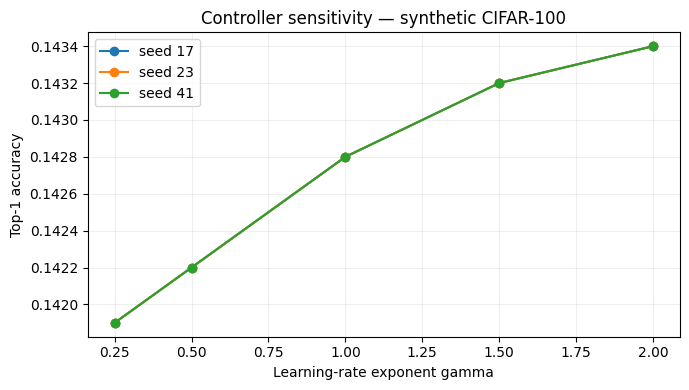

In [10]:
sev=PRED.groupby(['dataset','scenario','corruption','severity','method','seed'],as_index=False).agg(accuracy=('correct','mean'),n=('correct','size'))
sev.to_csv(ROOT/'severity_accuracy.csv',index=False)
phase=PRED.groupby(['dataset','scenario','method','seed','phase'],as_index=False).agg(accuracy=('correct','mean'),n=('correct','size'))
phase.to_csv(ROOT/'phase_accuracy.csv',index=False)
# Actual controller exponent sensitivity: new model for every exponent/seed, same image sequence.
sensitivity=[]
for gamma in ([0.5,1.,2.] if MODE=='verify' else [0.25,0.5,1.,1.5,2.]):
    for seed in SEEDS:
        path=ROOT/f'sensitivity_gamma{gamma}_seed{seed}.json'
        if path.exists():sensitivity.append(json.loads(path.read_text()));continue
        seed_all(seed)
        img,gt,meta=stream_for('CIFAR-100','abrupt',seed)
        adapter=Adapter(SOURCES['CIFAR-100'],'rg_attl',gamma=gamma)
        preds=[]
        for a in range(0,len(img),BATCH):
            pr,_=adapter.step(img[a:a+BATCH].to(DEVICE));preds.extend(pr.tolist())
        result={'gamma':gamma,'seed':seed,'accuracy':float((np.array(preds)==gt.numpy()).mean())}
        path.write_text(json.dumps(result));sensitivity.append(result)
        del adapter,img,gt;gc.collect()
        if DEVICE=='cuda':torch.cuda.empty_cache()
SENS=pd.DataFrame(sensitivity);SENS.to_csv(ROOT/'controller_sensitivity.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4))
for seed,g in SENS.groupby('seed'):
    ax.plot(g.gamma,g.accuracy,marker='o',label=f'seed {seed}')
ax.set(xlabel='Learning-rate exponent gamma',ylabel='Top-1 accuracy',title='Controller sensitivity — synthetic CIFAR-100');ax.grid(alpha=.2);ax.legend()
fig.tight_layout();fig.savefig(ROOT/'Figure_4_sensitivity.png',dpi=220);plt.show()


In [11]:
manifest={'title':'Adaptive Test-Time Learning for Robust Deep Neural Networks under Dynamic Distribution Shifts',
  'mode':MODE,'model':'CIFAR-compatible ResNet-18','datasets':DATASETS,
  'official_cifar10c':False,'cifar100_corruptions':'constructed synthetic, not CIFAR-100-C',
  'source_training_epochs':EPOCHS,'seeds':SEEDS,'train_count_requested':TRAIN_N,
  'test_count_requested':TEST_N,'completed_jobs':int(len(PERF)), 'expected_jobs':len(JOBS),
  'official_baselines_verified':False,
  'limitations':['Custom in-notebook EATA/SAR variants are not official reproductions',
     'Full training/robustness claims require adequate convergence and completed manuscript mode',
     'CIFAR-10 Kaggle competition labeled holdout is not official CIFAR-10 test if test labels absent',
     'Controller sensitivity requires additional actual runs of changed parameter values']}
(ROOT/'manifest.json').write_text(json.dumps(manifest,indent=2))
import shutil
out=shutil.make_archive(str(ROOT.parent/f'{MODE}_experiment_results'),'zip',ROOT)
print('Saved:',out)
print('Checkpoint and results directory:',ROOT)


Saved: /content/RG_ATTL_FINAL_RESULTS/RG_ATTL_CIFAR100_ONLY_v1/manuscript_experiment_results.zip
Checkpoint and results directory: /content/RG_ATTL_FINAL_RESULTS/RG_ATTL_CIFAR100_ONLY_v1/manuscript
